<a href="https://colab.research.google.com/github/mpsinghmandawariya/Task/blob/master/TASK2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install pandas numpy matplotlib seaborn openpyxl

In [3]:
pip install notebook jupyter notebook

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 68.5 MB/s eta 0:00:00


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/superstore.csv",encoding="windows-1252")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset loaded successfully!
Number of rows: 9994
Number of columns: 21


In [13]:

print("Rows and columns:", df.shape)
print("Total records:", len(df))
print("Total columns:", len(df.columns))

print(df.columns.tolist())

df.info()





Rows and columns: (9994, 21)
Total records: 9994
Total columns: 21
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   ob

In [15]:

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)


Duplicate rows: 0


In [16]:

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary


,Missing Values,Missing Percentage
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Customer Name,0,0.0
Segment,0,0.0
Country,0,0.0
City,0,0.0


In [18]:

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())


['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']


In [19]:

date_columns = ["order_date", "ship_date"]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(
            df[col],
            errors="coerce"
        )

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   row_id         9994 non-null   int64         
 1   order_id       9994 non-null   object        
 2   order_date     9994 non-null   datetime64[ns]
 3   ship_date      9994 non-null   datetime64[ns]
 4   ship_mode      9994 non-null   object        
 5   customer_id    9994 non-null   object        
 6   customer_name  9994 non-null   object        
 7   segment        9994 non-null   object        
 8   country        9994 non-null   object        
 9   city           9994 non-null   object        
 10  state          9994 non-null   object        
 11  postal_code    9994 non-null   int64         
 12  region         9994 non-null   object        
 13  product_id     9994 non-null   object        
 14  category       9994 non-null   object        
 15  sub_category   9994 n

In [20]:

numeric_columns = [
    "sales",
    "profit",
    "quantity",
    "discount",
    "shipping_cost"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   row_id         9994 non-null   int64         
 1   order_id       9994 non-null   object        
 2   order_date     9994 non-null   datetime64[ns]
 3   ship_date      9994 non-null   datetime64[ns]
 4   ship_mode      9994 non-null   object        
 5   customer_id    9994 non-null   object        
 6   customer_name  9994 non-null   object        
 7   segment        9994 non-null   object        
 8   country        9994 non-null   object        
 9   city           9994 non-null   object        
 10  state          9994 non-null   object        
 11  postal_code    9994 non-null   int64         
 12  region         9994 non-null   object        
 13  product_id     9994 non-null   object        
 14  category       9994 non-null   object        
 15  sub_category   9994 n

In [22]:

for col in ["sales", "profit", "quantity", "discount"]:
    if col in df.columns:
        print(f"\n{col}")
        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())
        print("Negative values:", (df[col] < 0).sum())



sales
Minimum: 0.444
Maximum: 22638.48
Negative values: 0

profit
Minimum: -6599.978
Maximum: 8399.976
Negative values: 1871

quantity
Minimum: 1
Maximum: 14
Negative values: 0

discount
Minimum: 0.0
Maximum: 0.8
Negative values: 0


In [23]:

outlier_columns = [
    col for col in ["sales", "profit", "quantity"]
    if col in df.columns
]

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\n{col}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Potential outliers:", len(outliers))



sales
Lower limit: -271.71000000000004
Upper limit: 498.93
Potential outliers: 1167

profit
Lower limit: -39.724125
Upper limit: 70.816875
Potential outliers: 1881

quantity
Lower limit: -2.5
Upper limit: 9.5
Potential outliers: 170


In [24]:

print("Final dataset shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFinal data types:")
print(df.dtypes)


Final dataset shape: (9994, 21)

Remaining missing values:
Series([], dtype: int64)

Duplicate rows: 0

Final data types:
row_id                    int64
order_id                 object
order_date       datetime64[ns]
ship_date        datetime64[ns]
ship_mode                object
customer_id              object
customer_name            object
segment                  object
country                  object
city                     object
state                    object
postal_code               int64
region                   object
product_id               object
category                 object
sub_category             object
product_name             object
sales                   float64
quantity                  int64
discount                float64
profit                  float64
dtype: object


In [26]:

unwanted_columns = [
    "row_id",
    "customer_name",
    "order_id",
    "postal_code"

]

df = df.drop(
    columns=[
        col for col in unwanted_columns
        if col in df.columns
    ]
)

print("Remaining columns:")
print(df.columns.tolist())

print("\nUpdated dataset shape:", df.shape)


Remaining columns:
['order_date', 'ship_date', 'ship_mode', 'customer_id', 'segment', 'country', 'city', 'state', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']

Updated dataset shape: (9994, 17)


In [27]:

df.to_csv("cleaned_superstore.csv", index=False)

print("Dataset saved after removing unwanted columns.")


Dataset saved after removing unwanted columns.


In [29]:

total_sales = df["sales"].sum()
total_profit = df["profit"].sum()

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")

if total_sales != 0:
    print(f"Profit Margin: {(total_profit / total_sales) * 100:.2f}%")


Total Sales: 2,297,200.86
Total Profit: 286,397.02
Profit Margin: 12.47%


In [30]:

print("Average Sales:", round(df["sales"].mean(), 2))
print("Average Profit:", round(df["profit"].mean(), 2))

if "quantity" in df.columns:
    print("Average Quantity:", round(df["quantity"].mean(), 2))


Average Sales: 229.86
Average Profit: 28.66
Average Quantity: 3.79


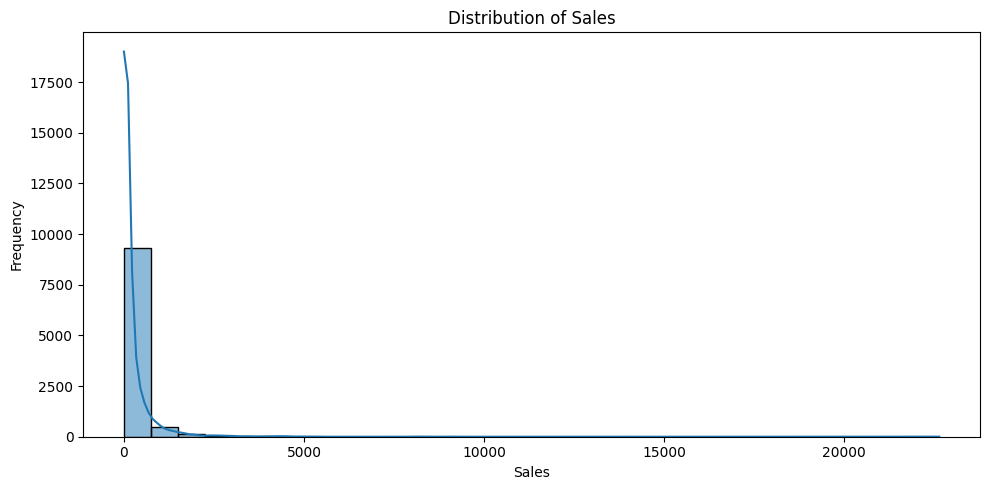

In [31]:

plt.figure(figsize=(10, 5))

sns.histplot(df["sales"], bins=30, kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


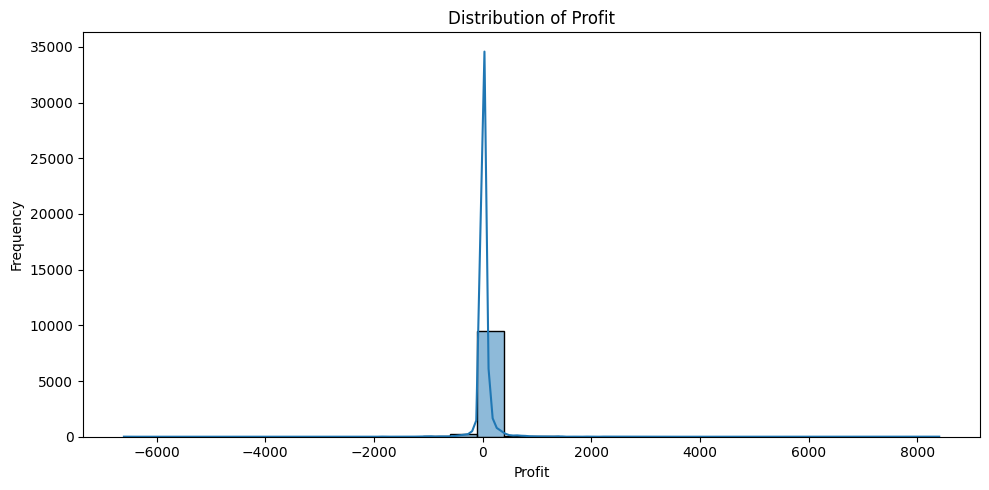

In [32]:

plt.figure(figsize=(10, 5))

sns.histplot(df["profit"], bins=30, kde=True)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [33]:

category_analysis = df.groupby("category").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum")
).sort_values("Total_Sales", ascending=False)

display(category_analysis)


,Total_Sales,Total_Profit
category,,
Technology,836154.0330,145454.9481
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008


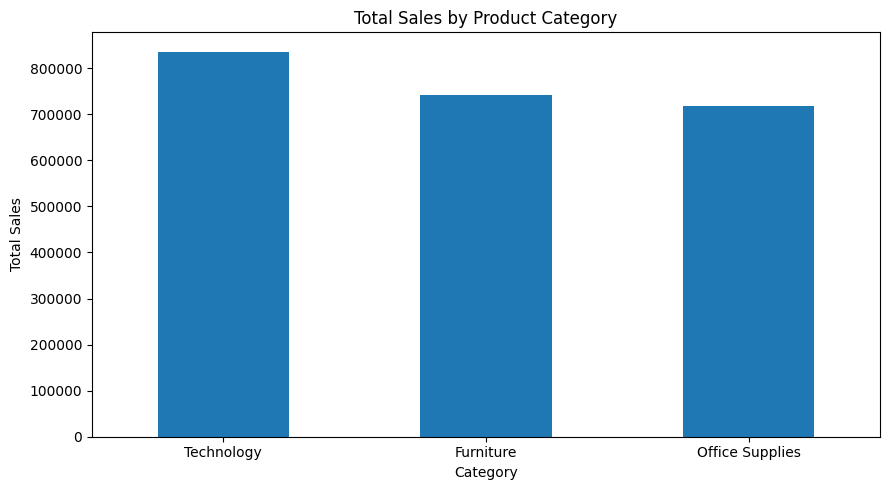

In [34]:

category_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [35]:

# Check that order_date exists
print(df.columns.tolist())

# Convert order_date to datetime
df["order_date"] = pd.to_datetime(
    df["order_date"],
    errors="coerce"
)

print(df["order_date"].dtype)


['order_date', 'ship_date', 'ship_mode', 'customer_id', 'segment', 'country', 'city', 'state', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']
datetime64[ns]


In [36]:

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month

df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

display(df[["order_date", "year", "month", "year_month"]].head())


,order_date,year,month,year_month
0,2016-11-08,2016,11,2016-11
1,2016-11-08,2016,11,2016-11
2,2016-06-12,2016,6,2016-06
3,2015-10-11,2015,10,2015-10
4,2015-10-11,2015,10,2015-10


In [37]:

monthly_sales = (
    df.groupby("year_month")["sales"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Year_Month", "Total_Sales"]

display(monthly_sales.head(10))


,Year_Month,Total_Sales
0,2014-01,14236.8950
1,2014-02,4519.8920
2,2014-03,55691.0090
3,2014-04,28295.3450
4,2014-05,23648.2870
5,2014-06,34595.1276
6,2014-07,33946.3930
7,2014-08,27909.4685
8,2014-09,81777.3508
9,2014-10,31453.3930


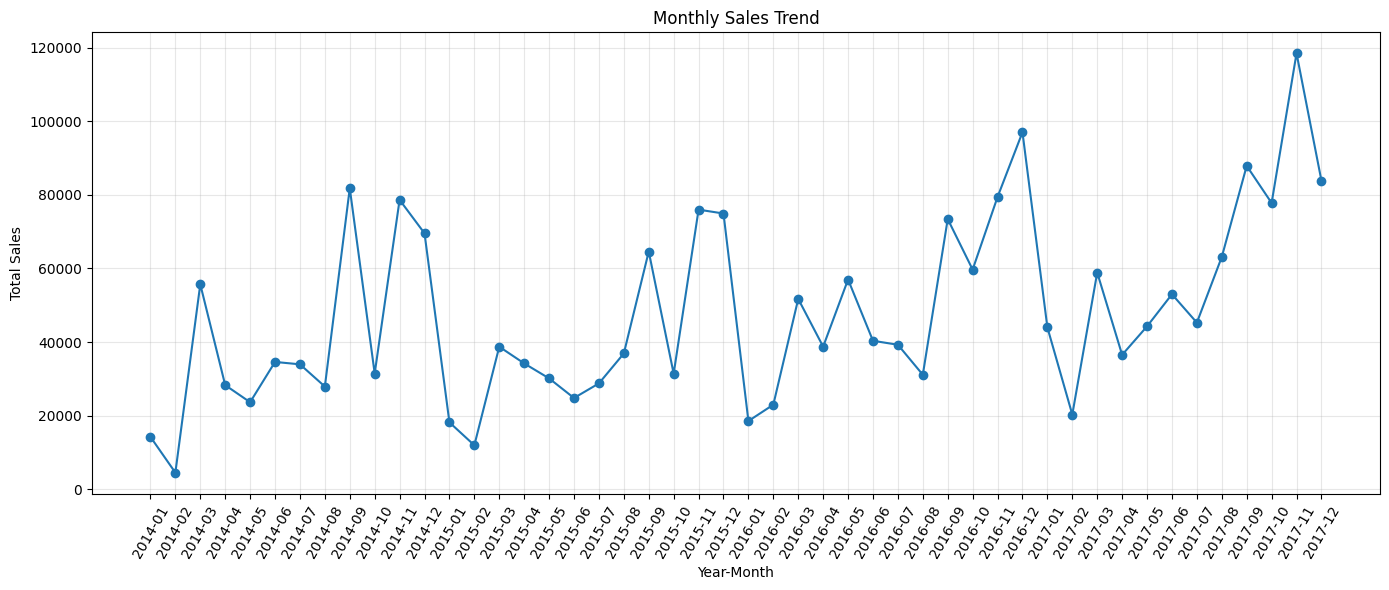

In [38]:

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Year_Month"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [39]:
best_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

worst_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmin()
]

print("Highest sales month:")
print(best_month)

print("\nLowest sales month:")
print(worst_month)


Highest sales month:
Year_Month        2017-11
Total_Sales    118447.825
Name: 46, dtype: object

Lowest sales month:
Year_Month      2014-02
Total_Sales    4519.892
Name: 1, dtype: object


In [40]:

monthly_profit = (
    df.groupby("year_month")["profit"]
    .sum()
    .reset_index()
)

monthly_profit.columns = ["Year_Month", "Total_Profit"]

display(monthly_profit.head(10))


,Year_Month,Total_Profit
0,2014-01,2450.1907
1,2014-02,862.3084
2,2014-03,498.7299
3,2014-04,3488.8352
4,2014-05,2738.7096
5,2014-06,4976.5244
6,2014-07,-841.4826
7,2014-08,5318.1050
8,2014-09,8328.0994
9,2014-10,3448.2573


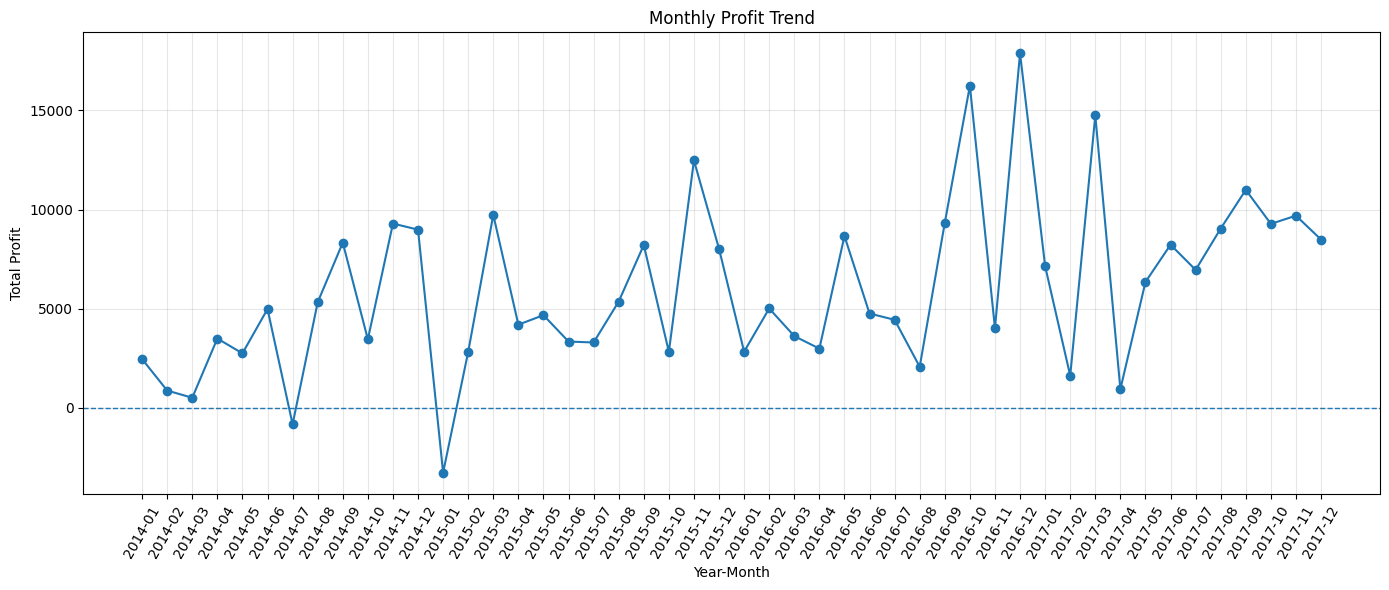

In [41]:

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_profit["Year_Month"],
    monthly_profit["Total_Profit"],
    marker="o"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Monthly Profit Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [42]:

monthly_comparison = monthly_sales.merge(
    monthly_profit,
    on="Year_Month",
    how="inner"
)

display(monthly_comparison.head(10))


,Year_Month,Total_Sales,Total_Profit
0,2014-01,14236.8950,2450.1907
1,2014-02,4519.8920,862.3084
2,2014-03,55691.0090,498.7299
3,2014-04,28295.3450,3488.8352
4,2014-05,23648.2870,2738.7096
5,2014-06,34595.1276,4976.5244
6,2014-07,33946.3930,-841.4826
7,2014-08,27909.4685,5318.1050
8,2014-09,81777.3508,8328.0994
9,2014-10,31453.3930,3448.2573


In [43]:

print(df.columns.tolist())

print("\nAvailable sub-categories:")
print(df["sub_category"].unique())


['order_date', 'ship_date', 'ship_mode', 'customer_id', 'segment', 'country', 'city', 'state', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'year', 'month', 'year_month']

Available sub-categories:
['Bookcases' 'Chairs' 'Labels' 'Tables' 'Storage' 'Furnishings' 'Art'
 'Phones' 'Binders' 'Appliances' 'Paper' 'Accessories' 'Envelopes'
 'Fasteners' 'Supplies' 'Machines' 'Copiers']


In [44]:

subcategory_analysis = df.groupby("sub_category").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum"),
    Total_Quantity=("quantity", "sum")
).sort_values("Total_Sales", ascending=False)

display(subcategory_analysis)


,Total_Sales,Total_Profit,Total_Quantity
sub_category,,,
Phones,330007.0540,44515.7306,3289
Chairs,328449.1030,26590.1663,2356
Storage,223843.6080,21278.8264,3158
Tables,206965.5320,-17725.4811,1241
Binders,203412.7330,30221.7633,5974
Machines,189238.6310,3384.7569,440
Accessories,167380.3180,41936.6357,2976
Copiers,149528.0300,55617.8249,234
Bookcases,114879.9963,-3472.5560,868


In [45]:

top_5_sales = subcategory_analysis.nlargest(5, "Total_Sales")

display(top_5_sales)


,Total_Sales,Total_Profit,Total_Quantity
sub_category,,,
Phones,330007.054,44515.7306,3289
Chairs,328449.103,26590.1663,2356
Storage,223843.608,21278.8264,3158
Tables,206965.532,-17725.4811,1241
Binders,203412.733,30221.7633,5974


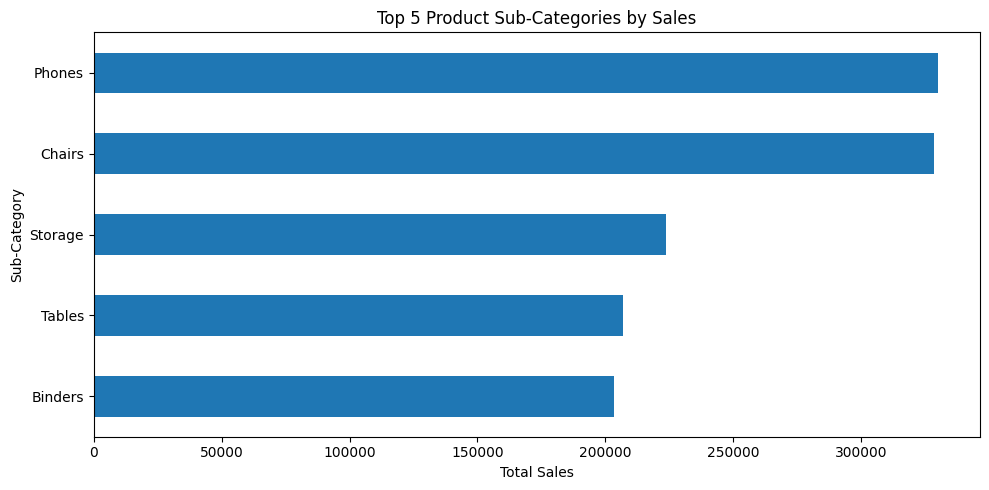

In [46]:

top_5_sales["Total_Sales"].sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Top 5 Product Sub-Categories by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()


In [47]:

top_5_profit = subcategory_analysis.nlargest(5, "Total_Profit")

display(top_5_profit)


,Total_Sales,Total_Profit,Total_Quantity
sub_category,,,
Copiers,149528.030,55617.8249,234
Phones,330007.054,44515.7306,3289
Accessories,167380.318,41936.6357,2976
Paper,78479.206,34053.5693,5178
Binders,203412.733,30221.7633,5974


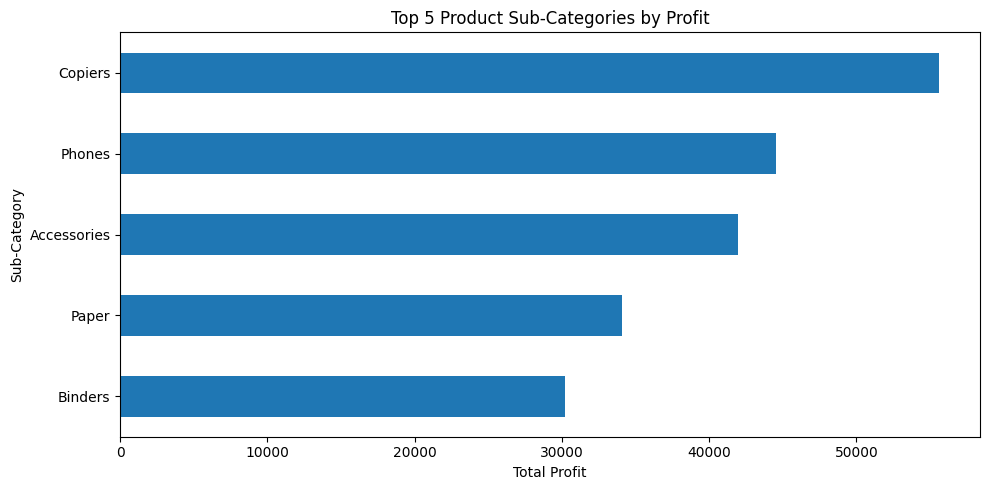

In [48]:

top_5_profit["Total_Profit"].sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Top 5 Product Sub-Categories by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()


In [49]:

bottom_5_profit = subcategory_analysis.nsmallest(5, "Total_Profit")

display(bottom_5_profit)


,Total_Sales,Total_Profit,Total_Quantity
sub_category,,,
Tables,206965.5320,-17725.4811,1241
Bookcases,114879.9963,-3472.5560,868
Supplies,46673.5380,-1189.0995,647
Fasteners,3024.2800,949.5182,914
Machines,189238.6310,3384.7569,440


In [50]:

subcategory_analysis["Profit_Margin_Percent"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"].replace(0, np.nan)
) * 100

display(
    subcategory_analysis.sort_values(
        "Profit_Margin_Percent",
        ascending=False
    )
)


,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_Percent
sub_category,,,,
Labels,12486.3120,5546.2540,1400,44.418672
Paper,78479.2060,34053.5693,5178,43.391837
Envelopes,16476.4020,6964.1767,906,42.267582
Copiers,149528.0300,55617.8249,234,37.195585
Fasteners,3024.2800,949.5182,914,31.396504
Accessories,167380.3180,41936.6357,2976,25.054700
Art,27118.7920,6527.7870,3000,24.071083
Appliances,107532.1610,18138.0054,1729,16.867517
Binders,203412.7330,30221.7633,5974,14.857361


In [56]:

segment_analysis = df.groupby("segment").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum"),
    Total_Quantity=("quantity", "sum")
).sort_values("Total_Sales", ascending=False)

display(segment_analysis)


,Total_Sales,Total_Profit,Total_Quantity
segment,,,
Consumer,1.161401e+06,134119.2092,19521
Corporate,7.061464e+05,91979.1340,11608
Home Office,4.296531e+05,60298.6785,6744


In [57]:

segment_analysis = df.groupby("segment").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum"),
    Total_Quantity=("quantity", "sum")
).sort_values("Total_Sales", ascending=False)

display(segment_analysis)


,Total_Sales,Total_Profit,Total_Quantity
segment,,,
Consumer,1.161401e+06,134119.2092,19521
Corporate,7.061464e+05,91979.1340,11608
Home Office,4.296531e+05,60298.6785,6744


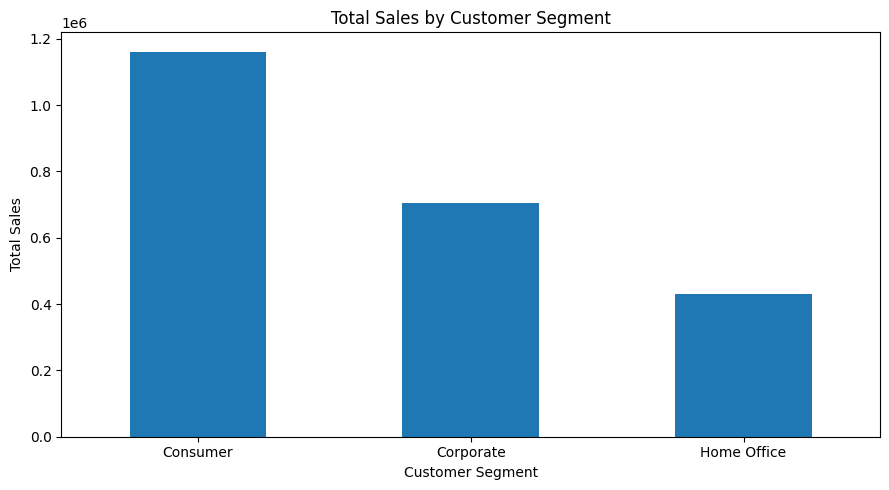

In [58]:

segment_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


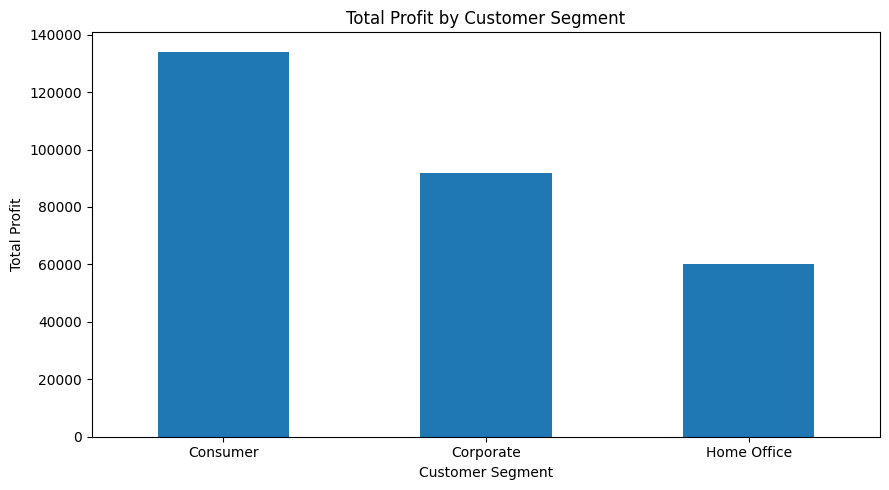

In [59]:

segment_analysis["Total_Profit"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Total Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [60]:

segment_analysis["Profit_Margin_Percent"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"].replace(0, np.nan)
) * 100

display(segment_analysis)


,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_Percent
segment,,,,
Consumer,1.161401e+06,134119.2092,19521,11.548050
Corporate,7.061464e+05,91979.1340,11608,13.025506
Home Office,4.296531e+05,60298.6785,6744,14.034269


In [61]:

print([col for col in df.columns if "region" in col or "state" in col])

region_analysis = df.groupby("region").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum"),
    Total_Quantity=("quantity", "sum")
).sort_values("Total_Sales", ascending=False)

display(region_analysis)


['state', 'region']


,Total_Sales,Total_Profit,Total_Quantity
region,,,
West,725457.8245,108418.4489,12266
East,678781.2400,91522.7800,10618
Central,501239.8908,39706.3625,8780
South,391721.9050,46749.4303,6209


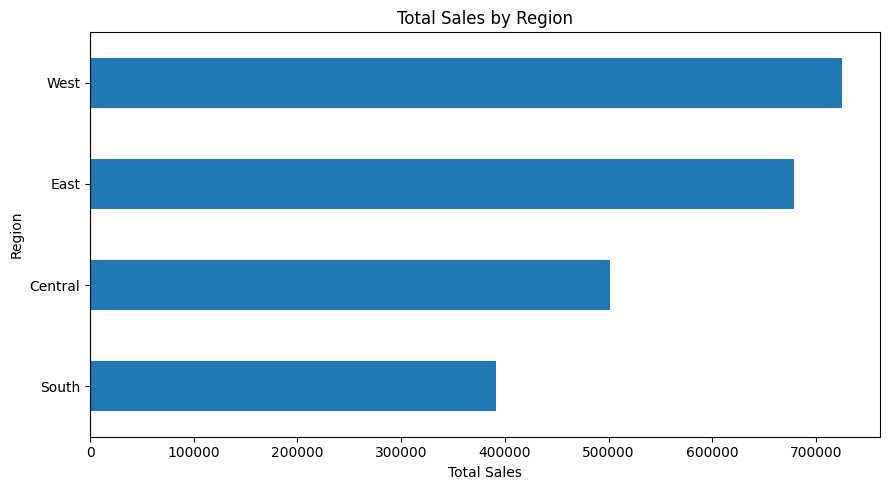

In [62]:

region_analysis["Total_Sales"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Total Sales by Region")
plt.xlabel("Total Sales")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


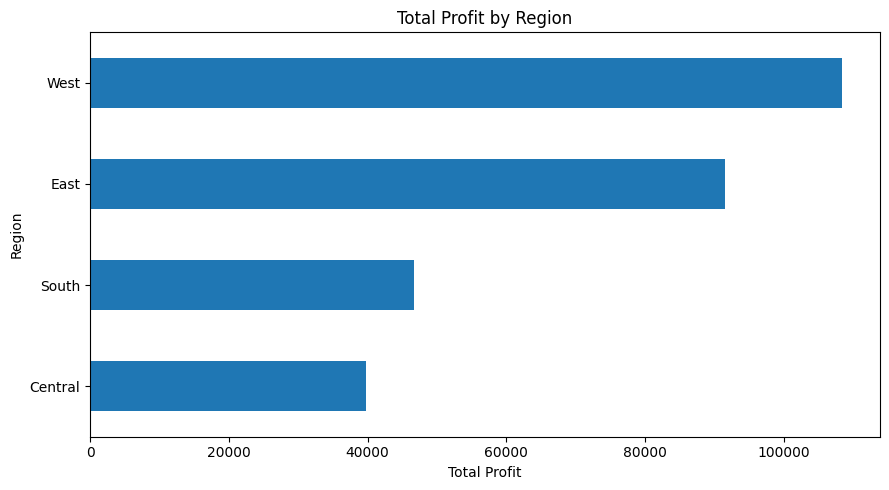

In [63]:

region_analysis["Total_Profit"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Total Profit by Region")
plt.xlabel("Total Profit")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


In [65]:

%pip install plotly

import plotly.express as px
import plotly.graph_objects as go

print("Plotly imported successfully!")


Plotly imported successfully!


In [66]:

monthly_sales_plot = (
    df.groupby("year_month", as_index=False)["sales"]
    .sum()
    .sort_values("year_month")
)

fig = px.line(
    monthly_sales_plot,
    x="year_month",
    y="sales",
    markers=True,
    title="Interactive Monthly Sales Trend",
    labels={
        "year_month": "Month",
        "sales": "Total Sales"
    }
)

fig.update_layout(hovermode="x unified")
fig.show()


In [67]:

if "category" in df.columns:
    category_sales = (
        df.groupby("category", as_index=False)["sales"]
        .sum()
        .sort_values("sales", ascending=False)
    )

    fig = px.bar(
        category_sales,
        x="category",
        y="sales",
        color="category",
        title="Interactive Sales by Product Category",
        labels={
            "category": "Product Category",
            "sales": "Total Sales"
        }
    )

    fig.show()
else:
    print("Category column not found.")


In [68]:

if "category" in df.columns:
    category_profit = (
        df.groupby("category", as_index=False)["profit"]
        .sum()
        .sort_values("profit", ascending=False)
    )

    fig = px.bar(
        category_profit,
        x="category",
        y="profit",
        color="profit",
        color_continuous_scale="RdYlGn",
        title="Interactive Profit by Product Category",
        labels={
            "category": "Product Category",
            "profit": "Total Profit"
        }
    )

    fig.show()
else:
    print("Category column not found.")


In [69]:

if "customer_segment" in df.columns:
    segment_data = (
        df.groupby("customer_segment", as_index=False)
        .agg(
            sales=("sales", "sum"),
            profit=("profit", "sum")
        )
    )

    fig = px.bar(
        segment_data,
        x="customer_segment",
        y=["sales", "profit"],
        barmode="group",
        title="Sales and Profit by Customer Segment",
        labels={
            "customer_segment": "Customer Segment",
            "value": "Amount",
            "variable": "Metric"
        }
    )

    fig.show()
else:
    print("Customer segment column not found.")


Customer segment column not found.


In [70]:

if "region" in df.columns:
    region_data = (
        df.groupby("region", as_index=False)
        .agg(
            sales=("sales", "sum"),
            profit=("profit", "sum")
        )
    )

    fig = px.bar(
        region_data,
        x="region",
        y=["sales", "profit"],
        barmode="group",
        title="Regional Sales and Profit Comparison",
        labels={
            "region": "Region",
            "value": "Amount",
            "variable": "Metric"
        }
    )

    fig.show()
else:
    print("Region column not found.")


In [71]:

if "category" in df.columns:
    margin_data = (
        df.groupby("category", as_index=False)
        .agg(
            sales=("sales", "sum"),
            profit=("profit", "sum")
        )
    )

    margin_data["profit_margin_percent"] = (
        margin_data["profit"]
        / margin_data["sales"].replace(0, np.nan)
    ) * 100

    fig = px.bar(
        margin_data,
        x="category",
        y="profit_margin_percent",
        color="profit_margin_percent",
        color_continuous_scale="RdYlGn",
        title="Profit Margin by Category",
        labels={
            "category": "Category",
            "profit_margin_percent": "Profit Margin (%)"
        }
    )

    fig.show()


In [72]:

import os

os.makedirs("charts", exist_ok=True)

fig.write_html("charts/profit_margin_by_category.html")

print("Interactive chart saved successfully!")


Interactive chart saved successfully!


In [73]:

total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique() if "order_id" in df.columns else None

print("========== BUSINESS PERFORMANCE ==========")
print(f"Total Sales:  {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")

if total_sales != 0:
    print(f"Profit Margin: {(total_profit / total_sales) * 100:.2f}%")

if total_orders is not None:
    print(f"Unique Orders: {total_orders:,}")


========== BUSINESS PERFORMANCE ==========
Total Sales:  2,297,200.86
Total Profit: 286,397.02
Profit Margin: 12.47%


In [74]:

category_insights = df.groupby("category").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum")
)

print("Highest Sales Category:")
display(category_insights.nlargest(1, "Total_Sales"))

print("Highest Profit Category:")
display(category_insights.nlargest(1, "Total_Profit"))

print("Lowest Profit Category:")
display(category_insights.nsmallest(1, "Total_Profit"))


Highest Sales Category:


,Total_Sales,Total_Profit
category,,
Technology,836154.033,145454.9481


Highest Profit Category:


,Total_Sales,Total_Profit
category,,
Technology,836154.033,145454.9481


Lowest Profit Category:


,Total_Sales,Total_Profit
category,,
Furniture,741999.7953,18451.2728


In [75]:

subcategory_insights = df.groupby("sub_category").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum")
)

print("Top 5 sub-categories by profit:")
display(subcategory_insights.nlargest(5, "Total_Profit"))

print("Bottom 5 sub-categories by profit:")
display(subcategory_insights.nsmallest(5, "Total_Profit"))


Top 5 sub-categories by profit:


,Total_Sales,Total_Profit
sub_category,,
Copiers,149528.030,55617.8249
Phones,330007.054,44515.7306
Accessories,167380.318,41936.6357
Paper,78479.206,34053.5693
Binders,203412.733,30221.7633


Bottom 5 sub-categories by profit:


,Total_Sales,Total_Profit
sub_category,,
Tables,206965.5320,-17725.4811
Bookcases,114879.9963,-3472.5560
Supplies,46673.5380,-1189.0995
Fasteners,3024.2800,949.5182
Machines,189238.6310,3384.7569


In [77]:

segment_insights = df.groupby("segment").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum")
)

segment_insights["Profit_Margin_Percent"] = (
    segment_insights["Total_Profit"]
    / segment_insights["Total_Sales"].replace(0, np.nan)
) * 100

display(segment_insights.sort_values("Total_Profit", ascending=False))


,Total_Sales,Total_Profit,Profit_Margin_Percent
segment,,,
Consumer,1.161401e+06,134119.2092,11.548050
Corporate,7.061464e+05,91979.1340,13.025506
Home Office,4.296531e+05,60298.6785,14.034269


In [78]:

region_insights = df.groupby("region").agg(
    Total_Sales=("sales", "sum"),
    Total_Profit=("profit", "sum")
)

display(region_insights.sort_values("Total_Profit", ascending=False))


,Total_Sales,Total_Profit
region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
South,391721.9050,46749.4303
Central,501239.8908,39706.3625


In [79]:

best_category_sales = category_insights["Total_Sales"].idxmax()
best_category_profit = category_insights["Total_Profit"].idxmax()
worst_category_profit = category_insights["Total_Profit"].idxmin()

best_subcategory = subcategory_insights["Total_Profit"].idxmax()
worst_subcategory = subcategory_insights["Total_Profit"].idxmin()

best_segment = segment_insights["Total_Profit"].idxmax()
best_region = region_insights["Total_Profit"].idxmax()

print("========== BUSINESS INSIGHTS ==========\n")

print(f"1. Highest-sales category: {best_category_sales}")
print(f"2. Most profitable category: {best_category_profit}")
print(f"3. Lowest-profit category: {worst_category_profit}")
print(f"4. Most profitable sub-category: {best_subcategory}")
print(f"5. Lowest-profit sub-category: {worst_subcategory}")
print(f"6. Most profitable customer segment: {best_segment}")
print(f"7. Most profitable region: {best_region}")

print("\n========== RECOMMENDATIONS ==========\n")
print(f"- Review inventory and marketing for {best_category_sales}.")
print(f"- Study pricing and costs in {worst_category_profit}.")
print(f"- Investigate the reasons for low profit in {worst_subcategory}.")
print(f"- Study successful strategies in the {best_segment} segment.")
print(f"- Examine sales and operational practices in the {best_region} region.")


========== BUSINESS INSIGHTS ==========

1. Highest-sales category: Technology
2. Most profitable category: Technology
3. Lowest-profit category: Furniture
4. Most profitable sub-category: Copiers
5. Lowest-profit sub-category: Tables
6. Most profitable customer segment: Consumer
7. Most profitable region: West

========== RECOMMENDATIONS ==========

- Review inventory and marketing for Technology.
- Study pricing and costs in Furniture.
- Investigate the reasons for low profit in Tables.
- Study successful strategies in the Consumer segment.
- Examine sales and operational practices in the West region.


In [81]:

df.to_csv("cleaned_superstore.csv", index=False)

print("Final cleaned dataset saved successfully!")


Final cleaned dataset saved successfully!


In [82]:

os.makedirs("results", exist_ok=True)

category_insights.to_csv("results/category_insights.csv")
subcategory_insights.to_csv("results/subcategory_insights.csv")
segment_insights.to_csv("results/segment_insights.csv")
region_insights.to_csv("results/region_insights.csv")

print("All analysis tables saved in the results folder!")


All analysis tables saved in the results folder!


In [83]:
print("Available columns:")
print(df.columns.tolist())

Available columns:
['order_date', 'ship_date', 'ship_mode', 'customer_id', 'segment', 'country', 'city', 'state', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'year', 'month', 'year_month']


In [84]:
segment_analysis = df.groupby("segment").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    total_quantity=("quantity", "sum")
).sort_values("total_sales", ascending=False)

segment_analysis["profit_margin_percent"] = (
    segment_analysis["total_profit"] /
    segment_analysis["total_sales"].replace(0, float("nan")) * 100
).round(2)

display(segment_analysis)

,total_sales,total_profit,total_quantity,profit_margin_percent
segment,,,,
Consumer,1.161401e+06,134119.2092,19521,11.55
Corporate,7.061464e+05,91979.1340,11608,13.03
Home Office,4.296531e+05,60298.6785,6744,14.03


In [85]:
import plotly.express as px

fig = px.bar(
    segment_analysis.reset_index(),
    x="segment",
    y="total_sales",
    color="segment",
    title="Total Sales by Customer Segment",
    labels={
        "segment": "Customer Segment",
        "total_sales": "Total Sales"
    },
    text_auto=".2s"
)

fig.show()

In [86]:
segment_comparison = segment_analysis.reset_index().melt(
    id_vars="segment",
    value_vars=["total_sales", "total_profit"],
    var_name="metric",
    value_name="amount"
)

fig = px.bar(
    segment_comparison,
    x="segment",
    y="amount",
    color="metric",
    barmode="group",
    title="Sales vs Profit by Customer Segment"
)

fig.show()

In [87]:
df.to_csv("cleaned_superstore.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [89]:
# Make sure order_date is in datetime format
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

# Extract year and month
df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

# Calculate monthly sales and profit
monthly_analysis = df.groupby("year_month").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    total_quantity=("quantity", "sum")
).reset_index()

display(monthly_analysis.head())

,year_month,total_sales,total_profit,total_quantity
0,2014-01,14236.895,2450.1907,284
1,2014-02,4519.892,862.3084,159
2,2014-03,55691.009,498.7299,585
3,2014-04,28295.345,3488.8352,536
4,2014-05,23648.287,2738.7096,466


In [90]:
segment_analysis.to_csv("segment_analysis.csv")

category_analysis.to_csv("category_analysis.csv")
subcategory_analysis.to_csv("subcategory_analysis.csv")
monthly_analysis.to_csv("monthly_analysis.csv")

print("Analysis result files saved successfully!")

Analysis result files saved successfully!


In [91]:
import pandas as pd
import numpy as np

# Load the cleaned dataset if df does not exist
if "df" not in globals():
    df = pd.read_csv("cleaned_superstore.csv")

# Check required columns
print("Columns:", df.columns.tolist())

# Convert date and sales columns
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

# Remove rows without a usable date or sales value
model_data = df.dropna(subset=["order_date", "sales"]).copy()

# Aggregate daily transactions into monthly sales
monthly_sales = (
    model_data
    .set_index("order_date")
    .resample("MS")["sales"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["date", "sales"]

print("Number of months:", len(monthly_sales))
display(monthly_sales.head())

Columns: ['order_date', 'ship_date', 'ship_mode', 'customer_id', 'segment', 'country', 'city', 'state', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'year', 'month', 'year_month']
Number of months: 48


,date,sales
0,2014-01-01,14236.895
1,2014-02-01,4519.892
2,2014-03-01,55691.009
3,2014-04-01,28295.345
4,2014-05-01,23648.287


In [92]:
# Create a chronological time index
monthly_sales["time_index"] = np.arange(len(monthly_sales))

# Capture recurring yearly seasonality
monthly_sales["month"] = monthly_sales["date"].dt.month

monthly_sales["month_sin"] = np.sin(
    2 * np.pi * monthly_sales["month"] / 12
)

monthly_sales["month_cos"] = np.cos(
    2 * np.pi * monthly_sales["month"] / 12
)

display(monthly_sales.head())

,date,sales,time_index,month,month_sin,month_cos
0,2014-01-01,14236.895,0,1,0.500000,8.660254e-01
1,2014-02-01,4519.892,1,2,0.866025,5.000000e-01
2,2014-03-01,55691.009,2,3,1.000000,6.123234e-17
3,2014-04-01,28295.345,3,4,0.866025,-5.000000e-01
4,2014-05-01,23648.287,4,5,0.500000,-8.660254e-01


In [93]:
from sklearn.linear_model import LinearRegression

features = ["time_index", "month_sin", "month_cos"]
X = monthly_sales[features]
y = monthly_sales["sales"]

# Chronological split: earlier months for training,
# later months for testing
split_index = int(len(monthly_sales) * 0.8)

if split_index < 3 or len(monthly_sales) - split_index < 1:
    raise ValueError(
        "There are too few months to train and test this model reliably."
    )

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict sales for the test period
y_pred = model.predict(X_test)

print("Training months:", len(X_train))
print("Testing months:", len(X_test))
print("Model training completed!")

Training months: 38
Testing months: 10
Model training completed!


In [94]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 13311.66
Root Mean Squared Error (RMSE): 18763.90
R² Score: 0.3799


In [95]:
import plotly.graph_objects as go

results = pd.DataFrame({
    "date": monthly_sales["date"].iloc[split_index:].values,
    "actual_sales": y_test.values,
    "predicted_sales": y_pred
})

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=results["date"],
    y=results["actual_sales"],
    mode="lines+markers",
    name="Actual Sales"
))

fig.add_trace(go.Scatter(
    x=results["date"],
    y=results["predicted_sales"],
    mode="lines+markers",
    name="Predicted Sales"
))

fig.update_layout(
    title="Monthly Sales Forecasting: Actual vs Predicted",
    xaxis_title="Month",
    yaxis_title="Sales",
    template="plotly_white"
)

fig.show()

In [96]:
# Train on all available monthly data
final_model = LinearRegression()
final_model.fit(
    monthly_sales[features],
    monthly_sales["sales"]
)

# Generate the next six months
last_date = monthly_sales["date"].max()

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=6,
    freq="MS"
)

future_data = pd.DataFrame({
    "date": future_dates
})

future_data["time_index"] = np.arange(
    len(monthly_sales),
    len(monthly_sales) + 6
)

future_data["month"] = future_data["date"].dt.month

future_data["month_sin"] = np.sin(
    2 * np.pi * future_data["month"] / 12
)

future_data["month_cos"] = np.cos(
    2 * np.pi * future_data["month"] / 12
)

future_data["predicted_sales"] = final_model.predict(
    future_data[features]
)

display(future_data[["date", "predicted_sales"]].round(2))

,date,predicted_sales
0,2018-01-01,69471.36
1,2018-02-01,61649.45
2,2018-03-01,55269.79
3,2018-04-01,52243.27
4,2018-05-01,53582.33
5,2018-06-01,59129.64


In [97]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=monthly_sales["date"],
    y=monthly_sales["sales"],
    mode="lines",
    name="Historical Sales"
))

fig.add_trace(go.Scatter(
    x=future_data["date"],
    y=future_data["predicted_sales"],
    mode="lines+markers",
    name="Forecast Sales",
    line=dict(dash="dash")
))

fig.update_layout(
    title="Store Sales Forecast for the Next 6 Months",
    xaxis_title="Month",
    yaxis_title="Sales",
    template="plotly_white"
)

fig.show()

In [98]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=monthly_sales["date"],
    y=monthly_sales["sales"],
    mode="lines",
    name="Historical Sales"
))

fig.add_trace(go.Scatter(
    x=future_data["date"],
    y=future_data["predicted_sales"],
    mode="lines+markers",
    name="Forecast Sales",
    line=dict(dash="dash")
))

fig.update_layout(
    title="Store Sales Forecast for the Next 6 Months",
    xaxis_title="Month",
    yaxis_title="Sales",
    template="plotly_white"
)

fig.show()

In [99]:
import joblib

joblib.dump(final_model, "monthly_sales_model.pkl")

results.to_csv("sales_model_test_results.csv", index=False)

future_data[["date", "predicted_sales"]].to_csv(
    "future_sales_forecast.csv",
    index=False
)

print("Model and forecasting results saved successfully!")

Model and forecasting results saved successfully!


In [100]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-" * 35)
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

MODEL EVALUATION
-----------------------------------
MAE  : 13311.66
RMSE : 18763.90
R²   : 0.3799
